# Model Development, Part II: training and tuning

Tables and figures for the training report. Everything here is read from `../results/part2/` (aggregate numbers written by
`scripts/train_prediction.py` and `scripts/fit_inference_causal.py`) and, for calibration and the comparison of the two
criteria, from the out-of-fold predictions in `../artifacts/part2/` (local only, never shared).

**No test-set results:** the IMPACT505 era is dropped before training. All prediction numbers are 5-fold
cross-validation inside the training eras (IMPACT341/410/468), plus the forward check (train IMPACT341+410,
validate IMPACT468).

In [1]:
import json, sys
from importlib.metadata import version
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display

sys.path.insert(0, "../src")
from chordsurv.data import load_landmark
from chordsurv.metrics import observed_risk

RES, ART = Path("../results/part2"), Path("../artifacts/part2")
FIG = Path("../reports/part2/figures"); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
INK2, MUTED, GRID, AXIS = "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SLOT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": AXIS,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
                     "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.labelcolor": INK2, "legend.frameon": False,
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left"})

S = {l: json.loads((RES / l / "summary.json").read_text()) for l in ["km", "coxnet", "xgb", "nn"]}
lm = load_landmark(); train = lm[~lm.test_era]
t, e = train.time.to_numpy(float), train.event.to_numpy(int)
print(f"training patients {len(train):,}; deaths within 12 months {S['km']['n_deaths_12m']:,}; "
      f"Kaplan-Meier 12-month risk {observed_risk(t, e):.3f}")
print({p: version(p) for p in ["numpy", "pandas", "scikit-learn", "scikit-survival", "xgboost", "torch", "lifelines", "statsmodels"]})

training patients 15,595; deaths within 12 months 2,995; Kaplan-Meier 12-month risk 0.194
{'numpy': '2.5.4', 'pandas': '2.3.3', 'scikit-learn': '1.9.1', 'scikit-survival': '0.28.0', 'xgboost': '3.4.1', 'torch': '2.15.0', 'lifelines': '0.30.3', 'statsmodels': '0.15.0'}


## 1. Cross-validated error that guided tuning (not a test-set comparison)
Brier score at 12 months with censoring weights (lower is better; the tuning criterion), time-dependent AUC and Uno's
C-index truncated at 12 months. Mean over 5 folds ± standard error. Skill = 1 − Brier / Brier of Kaplan–Meier by cancer type.

In [2]:
NAMES = {"km": "Kaplan-Meier by type", "coxnet": "Elastic-net Cox", "xgb": "XGBoost (IPCW log loss)", "nn": "Neural discrete-time"}
km_brier = S["km"]["feature_sets"]["km"]["cv"]["brier"]["mean"]
rows = []
for l, s in S.items():
    for fs, r in s["feature_sets"].items():
        cv, fw = r["cv"], r["forward_468"]
        rows.append({"model": NAMES[l], "features": fs,
                     "Brier": f"{cv['brier']['mean']:.4f} ± {cv['brier']['se']:.4f}", "skill": 1 - cv["brier"]["mean"] / km_brier,
                     "AUC(12)": f"{cv['auc']['mean']:.3f} ± {cv['auc']['se']:.3f}", "C-index": f"{cv['cindex']['mean']:.3f}",
                     "mean risk": cv["mean_risk"]["mean"], "forward Brier": fw["brier"], "forward AUC": fw["auc"]})
    if l == "xgb":
        alt = s["feature_sets"]["landmark"]["alternative_criterion_cox"]["cv"]
        rows.append({"model": "XGBoost (Cox loss, alternative)", "features": "landmark",
                     "Brier": f"{alt['brier']['mean']:.4f} ± {alt['brier']['se']:.4f}", "skill": 1 - alt["brier"]["mean"] / km_brier,
                     "AUC(12)": f"{alt['auc']['mean']:.3f} ± {alt['auc']['se']:.3f}", "C-index": f"{alt['cindex']['mean']:.3f}",
                     "mean risk": alt["mean_risk"]["mean"]})
cvtab = pd.DataFrame(rows)
cvtab.to_csv(RES / "cv_table.csv", index=False)
display(cvtab.style.format({"skill": "{:.1%}", "mean risk": "{:.3f}", "forward Brier": "{:.4f}", "forward AUC": "{:.3f}"}, na_rep="")
        .hide(axis="index"))

model,features,Brier,skill,AUC(12),C-index,mean risk,forward Brier,forward AUC
Kaplan-Meier by type,km,0.1507 ± 0.0001,0.0%,0.621 ± 0.000,0.611,0.194,0.1452,0.619
Elastic-net Cox,day0,0.1252 ± 0.0005,16.9%,0.816 ± 0.002,0.787,0.198,0.1258,0.800
Elastic-net Cox,landmark,0.1023 ± 0.0003,32.1%,0.877 ± 0.002,0.850,0.202,0.1025,0.863
Elastic-net Cox,landmark_counts,0.1019 ± 0.0004,32.4%,0.877 ± 0.002,0.850,0.202,0.1019,0.865
Elastic-net Cox,landmark_no_pdl1,0.1023 ± 0.0003,32.1%,0.877 ± 0.002,0.850,0.202,0.1025,0.864
XGBoost (IPCW log loss),day0,0.1214 ± 0.0006,19.5%,0.826 ± 0.002,0.796,0.192,0.1170,0.824
XGBoost (IPCW log loss),landmark,0.0991 ± 0.0004,34.3%,0.886 ± 0.001,0.858,0.195,0.0959,0.881
XGBoost (IPCW log loss),landmark_counts,0.0989 ± 0.0006,34.4%,0.886 ± 0.001,0.859,0.195,0.0955,0.882
XGBoost (IPCW log loss),landmark_no_pdl1,0.0990 ± 0.0004,34.3%,0.885 ± 0.001,0.858,0.195,0.0956,0.881
"XGBoost (Cox loss, alternative)",landmark,0.0996 ± 0.0005,33.9%,0.884 ± 0.001,0.857,0.209,,


### 1.1 Gaps that answer the question (cross-validated, so only a preview of the test)
* day-0 → landmark: what the first 6 months add;
* landmark → landmark + counts: how much is MSK's monitoring intensity;
* landmark → without PD-L1: how much rests on the drifting PD-L1 field.

In [3]:
gap = []
for l in ["coxnet", "xgb", "nn"]:
    f = S[l]["feature_sets"]
    b = {fs: f[fs]["cv"]["brier"]["mean"] for fs in f}
    a = {fs: f[fs]["cv"]["auc"]["mean"] for fs in f}
    gap.append({"model": NAMES[l], "Brier day0": b["day0"], "Brier landmark": b["landmark"],
                "AUC day0": a["day0"], "AUC landmark": a["landmark"], "AUC +counts": a["landmark_counts"],
                "AUC no PD-L1": a["landmark_no_pdl1"],
                "Brier gain day0->landmark": b["day0"] - b["landmark"], "Brier gain +counts": b["landmark"] - b["landmark_counts"]})
display(pd.DataFrame(gap).set_index("model").round(4))

,Brier day0,Brier landmark,AUC day0,AUC landmark,AUC +counts,AUC no PD-L1,Brier gain day0->landmark,Brier gain +counts
model,,,,,,,,
Elastic-net Cox,0.1252,0.1023,0.8159,0.8769,0.8769,0.8769,0.0229,0.0004
XGBoost (IPCW log loss),0.1214,0.0991,0.8262,0.8858,0.8861,0.8854,0.0223,0.0002
Neural discrete-time,0.1261,0.1027,0.8079,0.8775,0.8777,0.8774,0.0234,0.0001


## 2. Tuning
### 2.1 Elastic-net Cox: the cross-validation curve (landmark features)

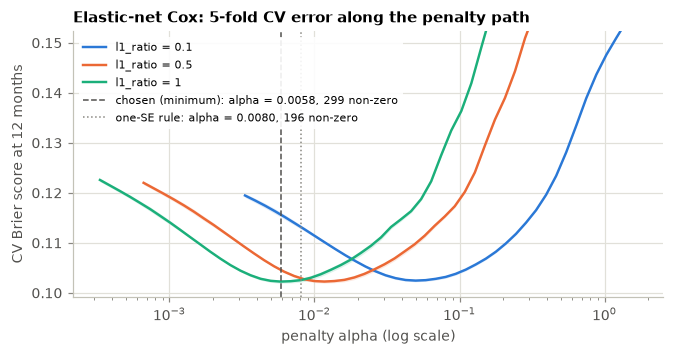

{'chosen_alpha_index': 21, 'edge_of_grid': False, 'nonzero_cv_mean': 314.4, 'n_features_with_interactions': 2051, 'one_se_rule': {'alpha': 0.008038290144661116, 'nonzero': 196.2, 'brier': 0.10255510916743989}}


In [4]:
sr = pd.read_csv(RES / "coxnet" / "search_landmark.csv")
ch = S["coxnet"]["feature_sets"]["landmark"]
fig, ax = plt.subplots(figsize=(6.2, 3.3))
for i, (l1, g) in enumerate(sr.groupby("l1_ratio")):
    g = g[g.n_folds == 5]
    ax.plot(g.alpha, g.brier, color=SLOT[i], lw=1.6, label=f"l1_ratio = {l1:g}")
    ax.fill_between(g.alpha, g.brier - g.brier_se, g.brier + g.brier_se, color=SLOT[i], alpha=0.15, lw=0)
ax.axvline(ch["params"]["alpha"], color=INK2, lw=1, ls="--",
           label=f"chosen (minimum): alpha = {ch['params']['alpha']:.4f}, {ch['final']['nonzero']} non-zero")
ax.axvline(ch["one_se_rule"]["alpha"], color=MUTED, lw=1, ls=":",
           label=f"one-SE rule: alpha = {ch['one_se_rule']['alpha']:.4f}, {ch['one_se_rule']['nonzero']:.0f} non-zero")
ax.set_xscale("log"); ax.set_xlabel("penalty alpha (log scale)"); ax.set_ylabel("CV Brier score at 12 months")
ax.set_ylim(sr.brier.min() - 0.003, sr.brier.min() + 0.05)
ax.set_title("Elastic-net Cox: 5-fold CV error along the penalty path"); ax.legend(loc="upper left", fontsize=7.5, frameon=True, framealpha=0.9, edgecolor="none")
fig.tight_layout(); fig.savefig(FIG / "cv_curve_coxnet.pdf"); fig.savefig(FIG / "cv_curve_coxnet.png", dpi=200); plt.show()
print({k: ch[k] for k in ["chosen_alpha_index", "edge_of_grid", "nonzero_cv_mean", "n_features_with_interactions", "one_se_rule"]})

### 2.2 Chosen hyperparameters and whether they sit at the edge of the search range

In [5]:
BOUNDS = {"xgb": {"learning_rate": (0.01, 0.3), "max_depth": (2, 8), "min_child_weight": (1, 100), "subsample": (0.5, 1),
                  "colsample_bytree": (0.2, 1), "reg_lambda": (0.1, 100), "reg_alpha": (1e-3, 10)},
          "nn": {"width": (32, 256), "depth": (1, 3), "dropout": (0, 0.5), "lr": (1e-4, 3e-3), "weight_decay": (1e-6, 0.1)}}
out = []
for l in ["coxnet", "xgb", "nn"]:
    for fs in ["day0", "landmark", "landmark_counts"]:
        p = S[l]["feature_sets"][fs]["params"]
        p = {k: v for k, v in p.items() if k != "alphas"}
        edge = []
        if l == "coxnet":
            edge = ["alpha"] if S[l]["feature_sets"][fs]["edge_of_grid"] else []
        else:                                                         # chosen value within 5 % of a bound
            for k, (lo, hi) in BOUNDS[l].items():
                pos = np.log(p[k] / lo) / np.log(hi / lo) if lo > 0 else (p[k] - lo) / (hi - lo)
                if pos < 0.05 or pos > 0.95:
                    edge.append(k)
        out.append({"model": NAMES[l], "features": fs, "chosen": {k: round(v, 4) if isinstance(v, float) else v for k, v in p.items()},
                    "at the edge": ", ".join(edge) or "none"})
display(pd.DataFrame(out))

,model,features,chosen,at the edge
0,Elastic-net Cox,day0,"{'l1_ratio': 1.0, 'alpha': 0.0059}",none
1,Elastic-net Cox,landmark,"{'l1_ratio': 1.0, 'alpha': 0.0058}",none
2,Elastic-net Cox,landmark_counts,"{'l1_ratio': 1.0, 'alpha': 0.0058}",none
3,XGBoost (IPCW log loss),day0,"{'learning_rate': 0.0199, 'max_depth': 7, 'min_child_weight': 4.0918, 'subsa...",none
4,XGBoost (IPCW log loss),landmark,"{'learning_rate': 0.0115, 'max_depth': 5, 'min_child_weight': 9.7271, 'subsa...",learning_rate
5,XGBoost (IPCW log loss),landmark_counts,"{'learning_rate': 0.0115, 'max_depth': 5, 'min_child_weight': 9.7271, 'subsa...",learning_rate
6,Neural discrete-time,day0,"{'width': 256, 'depth': 2, 'dropout': 0.4114, 'lr': 0.0005, 'weight_decay': ...",width
7,Neural discrete-time,landmark,"{'width': 256, 'depth': 2, 'dropout': 0.4114, 'lr': 0.0005, 'weight_decay': ...",width
8,Neural discrete-time,landmark_counts,"{'width': 64, 'depth': 2, 'dropout': 0.1905, 'lr': 0.0003, 'weight_decay': 0...",none


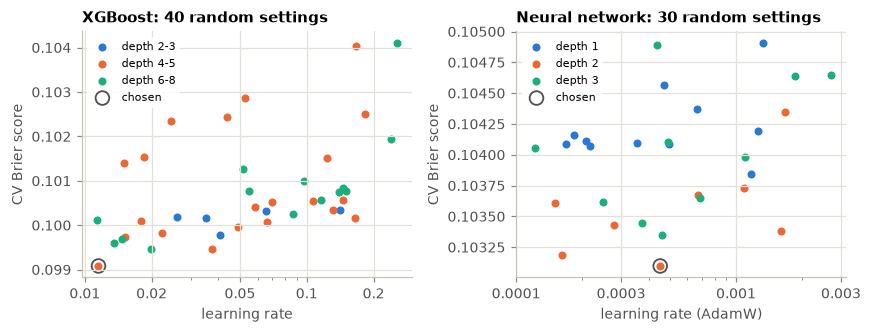

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.1), sharey=False)
for ax, (l, x, lab, ticks) in zip(axes, [("xgb", "learning_rate", "learning rate", [0.01, 0.02, 0.05, 0.1, 0.2]),
                                         ("nn", "lr", "learning rate (AdamW)", [1e-4, 3e-4, 1e-3, 3e-3])]):
    sr = pd.read_csv(RES / l / "search_landmark.csv")
    dcol = "max_depth" if l == "xgb" else "depth"
    groups_d = [(2, 3), (4, 5), (6, 8)] if l == "xgb" else [(1, 1), (2, 2), (3, 3)]
    for i, (lo, hi) in enumerate(groups_d):
        g = sr[sr[dcol].between(lo, hi)]
        ax.scatter(g[x], g.brier, s=18, color=SLOT[i], label=f"depth {lo}" if lo == hi else f"depth {lo}-{hi}")
    best = sr.loc[sr.brier.idxmin()]
    ax.scatter([best[x]], [best.brier], s=80, facecolors="none", edgecolors=INK2, lw=1.2, label="chosen")
    ax.set_xscale("log"); ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}")); ax.xaxis.set_minor_formatter(mtick.NullFormatter())
    ax.set_xlabel(lab); ax.set_ylabel("CV Brier score")
    ax.legend(fontsize=7, loc="upper left", frameon=True, framealpha=0.9, edgecolor="none")
    ax.set_title("XGBoost: 40 random settings" if l == "xgb" else "Neural network: 30 random settings")
fig.tight_layout(); fig.savefig(FIG / "random_search.pdf"); fig.savefig(FIG / "random_search.png", dpi=200); plt.show()

### 2.3 Extending the search where the choice sat at the edge
Where a chosen value lay within 5 % of a bound of its range, the chosen settings were refitted in the same folds beyond
that bound (`scripts/extend_search.py`): XGBoost's learning rate (0.0115, lower bound 0.01) and the network's width
(256, the largest offered). The choice changes only if the error improves by more than one standard error.

In [7]:
for f in sorted(RES.glob("*/edge_extension_*.csv")):
    l, fs = f.parent.name, f.stem.replace("edge_extension_", "")
    key = "learning_rate" if l == "xgb" else "width"
    ex = pd.read_csv(f)
    agg = ex.groupby(key).agg(brier=("brier", "mean"), brier_se=("brier", lambda x: x.std() / np.sqrt(len(x))), auc=("auc", "mean"))
    if "trees" in ex:
        agg["trees"] = ex.groupby(key).trees.mean()
    print(f"{NAMES[l]}, {fs} features"); display(agg.round(5))

Neural discrete-time, day0 features


,brier,brier_se,auc
width,,,
256,0.12668,0.00059,0.80484
512,0.12732,0.00071,0.80450


Neural discrete-time, landmark features


,brier,brier_se,auc
width,,,
256,0.10310,0.00064,0.87635
512,0.10375,0.00053,0.87564


XGBoost (IPCW log loss), landmark features


,brier,brier_se,auc,trees
learning_rate,,,,
0.00300,0.09893,0.00033,0.88592,4468.4
0.00600,0.09889,0.00034,0.88599,2349.2
0.01152,0.09908,0.00039,0.88577,1249.4


XGBoost (IPCW log loss), landmark_counts features


,brier,brier_se,auc,trees
learning_rate,,,,
0.00300,0.09873,0.00036,0.88624,4309.6
0.00600,0.09871,0.00048,0.88623,2259.8
0.01152,0.09886,0.00057,0.88606,1201.4


## 3. The criterion: XGBoost with IPCW log loss vs the alternative Cox partial likelihood
Same trees settings, only the loss changes. The IPCW log loss targets the 12-month risk directly. The Cox loss
targets the ranking of hazards and needs a Breslow baseline to give a 12-month risk.

{'spearman_with_ipcw_oof': 0.9896554243192492, 'mean_abs_risk_difference': 0.02770229069633086, 'cv_trees_mean': 853.0, 'final_trees': 1383}


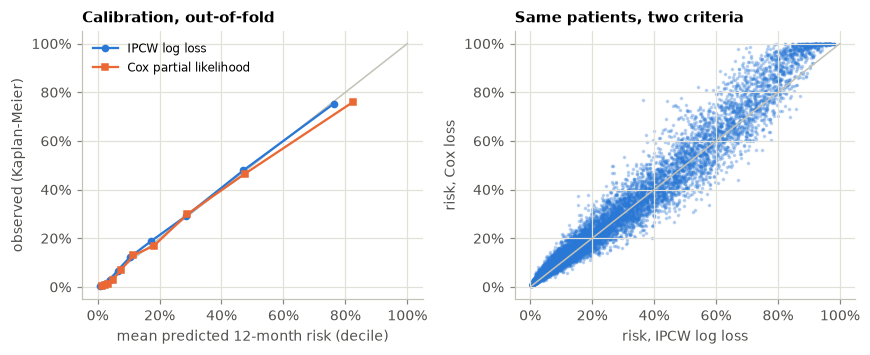

IPCW                Cox         
  predicted observed predicted observed
0     0.009    0.005     0.014    0.006
1     0.016    0.009     0.023    0.009
2     0.025    0.011     0.034    0.013
3     0.040    0.029     0.050    0.030
4     0.064    0.068     0.075    0.069
5     0.104    0.122     0.116    0.130
6     0.173    0.189     0.182    0.169
7     0.284    0.290     0.290    0.300
8     0.471    0.479     0.477    0.466
9     0.762    0.753     0.825    0.761

In [8]:
oof_ipcw = pd.read_parquet(ART / "oof_xgb_landmark.parquet").risk.reindex(train.index).to_numpy()
oof_cox = pd.read_parquet(ART / "oof_xgb_landmark_coxloss.parquet").risk.reindex(train.index).to_numpy()
alt = S["xgb"]["feature_sets"]["landmark"]["alternative_criterion_cox"]
print({k: alt[k] for k in ["spearman_with_ipcw_oof", "mean_abs_risk_difference", "cv_trees_mean", "final_trees"]})

def calib(risk, q=10):
    g = pd.qcut(risk, q, labels=False, duplicates="drop")
    return pd.DataFrame([{"predicted": risk[g == k].mean(), "observed": observed_risk(t[g == k], e[g == k])} for k in np.unique(g)])

c1, c2 = calib(oof_ipcw), calib(oof_cox)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.3))
ax = axes[0]
ax.plot([0, 1], [0, 1], color=AXIS, lw=1)
ax.plot(c1.predicted, c1.observed, "o-", color=SLOT[0], ms=4, label="IPCW log loss")
ax.plot(c2.predicted, c2.observed, "s-", color=SLOT[1], ms=4, label="Cox partial likelihood")
ax.set_xlabel("mean predicted 12-month risk (decile)"); ax.set_ylabel("observed (Kaplan-Meier)")
ax.set_title("Calibration, out-of-fold"); ax.legend(fontsize=8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax = axes[1]
ax.scatter(oof_ipcw, oof_cox, s=2, alpha=0.25, color=SLOT[0], rasterized=True)
ax.plot([0, 1], [0, 1], color=AXIS, lw=1)
ax.set_xlabel("risk, IPCW log loss"); ax.set_ylabel("risk, Cox loss"); ax.set_title("Same patients, two criteria")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
fig.tight_layout(); fig.savefig(FIG / "criterion_xgb.pdf"); fig.savefig(FIG / "criterion_xgb.png", dpi=200); plt.show()
display(pd.concat({"IPCW": c1, "Cox": c2}, axis=1).round(3))

## 4. Estimated parameters (final fits on all training eras)

In [9]:
cf = S["coxnet"]["feature_sets"]["landmark"]["final"]
print(f"Elastic-net Cox: {cf['nonzero']} non-zero of {S['coxnet']['feature_sets']['landmark']['n_features_with_interactions']} "
      f"({cf['nonzero_main']} shared effects, {cf['nonzero_interactions']} cancer-type deviations)")
display(pd.DataFrame(cf["top_coefficients"], columns=["feature", "coef (per SD)", "HR per SD"]).head(15).round(3))
xf = S["xgb"]["feature_sets"]["landmark"]["final"]
print(f"XGBoost: {xf['trees']} trees")
display(pd.DataFrame(xf["importance_total_gain"], columns=["feature", "share of total gain"]).round(3))
nf = S["nn"]["feature_sets"]["landmark"]["final"]
print(f"Neural network: {nf[0]['n_params']:,} weights per seed, {len(nf)} seeds averaged; settings {S['nn']['feature_sets']['landmark']['params']}")

Elastic-net Cox: 299 non-zero of 2051 (79 shared effects, 220 cancer-type deviations)


,feature,coef (per SD),HR per SD
0,win_on_systemic_tx_at_landmark,-0.235,0.791
1,lm_n_sites,0.195,1.216
2,win_ecog_last,0.194,1.214
3,d0_psa:Prostate Cancer,0.176,1.192
4,hr_positive:Breast Cancer,-0.173,0.841
5,win_presence_mean,0.155,1.168
6,win_prog_max,0.153,1.165
7,win_tx_chemo,0.141,1.151
8,pre_tx_chemo,0.139,1.149
9,win_psa_logratio,0.130,1.139


XGBoost: 1429 trees


,feature,share of total gain
0,win_prog_max,0.156
1,win_prog_mean,0.073
2,lm_n_sites,0.049
3,win_prog_last,0.043
4,lm_prog_max_recent,0.037
5,win_presence_mean,0.033
6,lm_cea,0.029
7,win_ecog_last,0.028
8,dx_to_seq_days,0.023
9,cancer_type_detailed_Pancreatic Adenocarcinoma,0.019


Neural network: 188,428 weights per seed, 5 seeds averaged; settings {'width': 256, 'depth': 2, 'dropout': 0.411380806635415, 'lr': 0.000451831534028514, 'weight_decay': 1.3683386964345506e-05}


## 5. Optimizer settings and convergence checks

In [10]:
rows = []
for fs in ["day0", "landmark", "landmark_counts", "landmark_no_pdl1"]:
    c = S["coxnet"]["feature_sets"][fs]["final"]
    x = S["xgb"]["feature_sets"][fs]["final"]
    n = S["nn"]["feature_sets"][fs]
    rows.append({"features": fs, "Cox KKT/alpha": c["kkt_violation_rel_tol1e-10"], "Cox path steps": c["path_length"],
                 "XGB trees": x["trees"], "XGB early-stopped": x["stopped_by_early_stopping"],
                 "NN best epochs": [s["best_epoch"] for s in n["final"]], "NN max |grad|": max(s["grad_norm"] for s in n["final"]),
                 "NN CV Brier spread over seeds": n["seeds"]["spread"]})
display(pd.DataFrame(rows).round(5))
print("default tolerance 1e-7 for comparison:", S["coxnet"]["feature_sets"]["landmark"]["final"]["default_tol_1e-7"])

,features,Cox KKT/alpha,Cox path steps,XGB trees,XGB early-stopped,NN best epochs,NN max |grad|,NN CV Brier spread over seeds
0,day0,0.00062,18,1364,True,"[6, 6, 6, 6, 6]",0.06596,0.00021
1,landmark,0.00125,22,1429,True,"[6, 6, 5, 5, 5]",0.08524,0.00040
2,landmark_counts,0.00142,22,1435,True,"[14, 15, 14, 13, 15]",0.06692,0.00074
3,landmark_no_pdl1,0.00125,22,1669,True,"[6, 6, 6, 5, 5]",0.08453,0.00041


default tolerance 1e-7 for comparison: {'kkt_violation_rel': 0.05670376528438586, 'max_abs_risk_difference': 0.00522680479886517, 'max_abs_coef_difference': 0.004880713489143318}


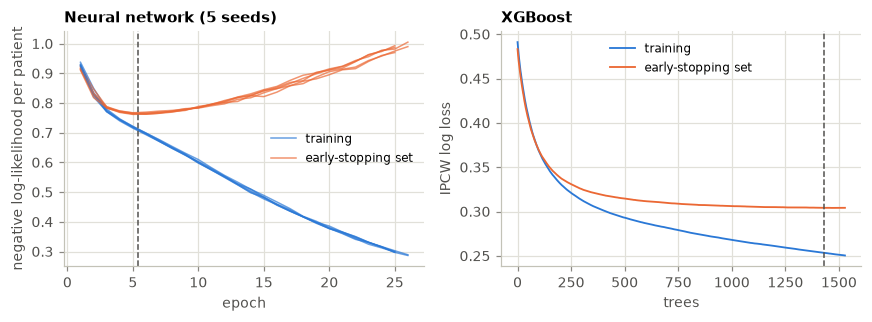

In [11]:
cur = pd.read_csv(RES / "nn" / "final_curve_landmark.csv")
best_ep = [s["best_epoch"] for s in S["nn"]["feature_sets"]["landmark"]["final"]]
fig, axes = plt.subplots(1, 2, figsize=(8, 3.0))
for i, (s, g) in enumerate(cur.groupby("seed")):
    axes[0].plot(g.epoch, g.train_loss, color=SLOT[0], lw=1, alpha=0.7, label="training" if i == 0 else None)
    axes[0].plot(g.epoch, g.es_loss, color=SLOT[1], lw=1, alpha=0.7, label="early-stopping set" if i == 0 else None)
axes[0].axvline(np.mean(best_ep), color=INK2, lw=1, ls="--")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("negative log-likelihood per patient")
axes[0].set_title("Neural network (5 seeds)"); axes[0].legend(fontsize=8)
xc = pd.read_csv(RES / "xgb" / "final_curve_landmark.csv")
axes[1].plot(xc["round"], xc.train, color=SLOT[0], lw=1.2, label="training")
axes[1].plot(xc["round"], xc.es, color=SLOT[1], lw=1.2, label="early-stopping set")
axes[1].axvline(S["xgb"]["feature_sets"]["landmark"]["final"]["trees"], color=INK2, lw=1, ls="--")
axes[1].set_xlabel("trees"); axes[1].set_ylabel("IPCW log loss"); axes[1].set_title("XGBoost"); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "convergence.pdf"); fig.savefig(FIG / "convergence.png", dpi=200); plt.show()

## 6. Cross-validated error within each cancer type (landmark features)

In [12]:
bt = {NAMES[l]: pd.read_csv(RES / l / f"by_type_{'km' if l == 'km' else 'landmark'}.csv", index_col=0) for l in ["km", "coxnet", "xgb", "nn"]}
display(pd.concat({k: v[["brier", "auc", "mean_risk"]] for k, v in bt.items()}, axis=1).round(3))

Kaplan-Meier by type                  Elastic-net Cox                  XGBoost (IPCW log loss)                  Neural discrete-time                 
                                          brier    auc mean_risk           brier    auc mean_risk                   brier    auc mean_risk                brier    auc mean_risk
Breast Cancer                             0.119  0.498     0.138           0.079  0.895     0.145                   0.076  0.905     0.138                0.080  0.897     0.129
Colorectal Cancer                         0.141  0.499     0.170           0.094  0.877     0.184                   0.092  0.883     0.180                0.094  0.873     0.166
Non-Small Cell Lung Cancer                0.176  0.500     0.227           0.125  0.836     0.231                   0.121  0.848     0.224                0.125  0.839     0.218
Pancreatic Cancer                         0.237  0.497     0.386           0.164  0.828     0.388                   0.154  0.847     0.383                0.163  0.830     0.373
Prostate Cancer                           0.104  0.497     0.118           0.061  0.907     0.130                   0.063  0.910     0.118                0.062  0.913     0.109

## 7. Description / inference (D1): 24-month survival from first sequencing
Kaplan–Meier with Greenwood standard errors (95 % log(−log) intervals), checked against a patient bootstrap, and
the era-standardised estimate (Kaplan–Meier within each panel era, weighted by the era's share of patients).

In [13]:
inf = pd.read_csv(RES / "inference" / "s24_by_type.csv", index_col=0)
display(inf[["n", "deaths", "S", "se", "se_bootstrap", "lo", "hi", "S_era_standardised", "se_era_standardised", "median_months"]].round(4))
print(json.loads((RES / "inference" / "summary.json").read_text()))
era = pd.read_csv(RES / "inference" / "s24_by_type_era.csv")
display(era.pivot(index="cancer_type", columns="era", values="S").round(3))

,n,deaths,S,se,se_bootstrap,lo,hi,S_era_standardised,se_era_standardised,median_months
cancer_type,,,,,,,,,,
Breast Cancer,5357,1986,0.7584,0.0061,0.0061,0.7462,0.7701,0.7593,0.0061,85.6437
Colorectal Cancer,5529,2213,0.7143,0.0066,0.0068,0.7013,0.7269,0.7179,0.0066,53.0958
Non-Small Cell Lung Cancer,7766,3953,0.6101,0.0058,0.0058,0.5986,0.6214,0.6136,0.0058,39.8137
Pancreatic Cancer,3094,2109,0.3883,0.0095,0.0093,0.3696,0.4070,0.3862,0.0099,17.5233
Prostate Cancer,3202,1034,0.7959,0.0076,0.0076,0.7806,0.8103,0.7959,0.0078,83.4739


{'estimand': 'S_c(24) = P(alive 24 months after first sequencing), MSK-sequenced patients', 'estimator': 'Kaplan-Meier; Greenwood SE; 95 % log(-log) CI; era-standardised KM as alternative', 'n': 24948, 'bootstrap_reps': 1000, 'logrank_chi2': 2068.2398201172214, 'logrank_df': 4, 'logrank_p': 0.0, 'max_abs_pooled_minus_standardised_pp': 0.35782690687644614}


era,IMPACT341,IMPACT410,IMPACT468,IMPACT505
cancer_type,,,,
Breast Cancer,0.560,0.674,0.795,0.777
Colorectal Cancer,0.534,0.658,0.720,0.762
Non-Small Cell Lung Cancer,0.382,0.582,0.624,0.649
Pancreatic Cancer,0.473,0.424,0.377,0.379
Prostate Cancer,0.757,0.740,0.802,0.822


## 8. Causal (C1): immunotherapy-containing first regimen vs chemotherapy alone, stage 4 NSCLC
Stabilised IPTW from a logistic propensity model (Newton–Raphson). Weighted Kaplan–Meier S(24) from treatment start
and a weighted Cox HR over the first 24 months. Bootstrap (1,000 replicates, propensity re-estimated in each) for the
intervals. The robust (sandwich) SE treats the weights as known.

In [14]:
cs = json.loads((RES / "causal" / "summary.json").read_text())
rows = []
for k, r in cs.items():
    if k == "crude_unweighted":
        rows.append({"analysis": k, "S(24) immuno": r["S1"], "S(24) chemo": r["S0"], "difference": r["diff"], "HR": r["hr"]})
        continue
    rows.append({"analysis": k, "n": f"{r['n_treated']}/{r['n_control']}", "ESS": f"{r['ess_treated']:.0f}/{r['ess_control']:.0f}",
                 "S(24) immuno": r["S1"], "S(24) chemo": r["S0"], "difference": r["diff"],
                 "diff 95% CI": f"[{r['diff_ci_boot'][0]:+.3f}, {r['diff_ci_boot'][1]:+.3f}]", "diff SE": r["diff_se_boot"],
                 "HR": r["hr"], "HR 95% CI (boot)": f"[{r['hr_ci_boot'][0]:.2f}, {r['hr_ci_boot'][1]:.2f}]",
                 "HR 95% CI (robust)": f"[{r['hr_ci_robust'][0]:.2f}, {r['hr_ci_robust'][1]:.2f}]",
                 "max |SMD| weighted": r["max_abs_smd_weighted"], "E-value": r["e_value_point"]})
display(pd.DataFrame(rows).round(3))
p = cs["primary_iptw"]["propensity"]
print(f"propensity model: converged {p['converged']} in {p['iterations']} Newton iterations, max |score| {p['max_abs_gradient']:.1e}")
display(pd.read_csv(RES / "causal" / "balance_smd.csv", index_col=0).round(2).T)

,analysis,n,ESS,S(24) immuno,S(24) chemo,difference,diff 95% CI,diff SE,HR,HR 95% CI (boot),HR 95% CI (robust),max |SMD| weighted,E-value
0,primary_iptw,470/186,441/122,0.373,0.355,0.018,"[-0.078, +0.121]",0.051,0.985,"[0.77, 1.24]","[0.76, 1.27]",0.086,1.114
1,crude_unweighted,NaN,NaN,0.378,0.360,0.018,NaN,NaN,0.987,NaN,NaN,NaN,NaN
2,without_pdl1,470/186,452/130,0.381,0.358,0.023,"[-0.068, +0.118]",0.048,0.976,"[0.77, 1.23]","[0.76, 1.25]",0.061,1.150
3,weights_truncated_1_99,470/186,441/139,0.373,0.359,0.014,"[-0.079, +0.109]",0.048,1.002,"[0.80, 1.26]","[0.79, 1.28]",0.090,1.041
4,overlap_weights,470/186,349/173,0.365,0.348,0.017,"[-0.074, +0.109]",0.046,1.006,"[0.80, 1.25]","[0.80, 1.27]",0.000,1.070
5,immuno_plus_chemo_only,301/186,273/101,0.323,0.348,-0.026,"[-0.140, +0.082]",0.057,1.067,"[0.79, 1.44]","[0.80, 1.43]",0.096,1.265
6,grace_period_42d,451/162,421/83,0.386,0.333,0.053,"[-0.072, +0.157]",0.058,0.850,"[0.63, 1.18]","[0.63, 1.14]",0.130,1.484
7,calendar_time_proxy,470/186,31/69,0.297,0.338,-0.040,"[-0.198, +0.122]",0.081,1.350,"[0.83, 2.15]","[0.86, 2.12]",0.451,1.764
8,calendar_time_proxy_overlap,470/186,263/139,0.346,0.360,-0.013,"[-0.115, +0.087]",0.051,1.111,"[0.88, 1.42]","[0.86, 1.44]",0.000,1.362


propensity model: converged True in 6 Newton iterations, max |score| 2.8e-14


,era_505,squamous,adenocarcinoma,male,white,never_smoker,ecog_0,ecog_2plus,ecog_missing,pdl1_positive,...,site_cns_brain,site_liver,site_bone,n_sites,log_tmb,mut_KRAS,mut_STK11,mut_KEAP1,mut_TP53,log_days_dx_to_seq
unweighted,0.45,0.01,-0.02,0.11,-0.05,-0.10,-0.00,0.07,-0.06,0.46,...,0.21,-0.11,0.12,0.22,0.05,0.20,-0.07,0.11,0.00,0.15
weighted,0.04,-0.08,0.02,0.04,-0.04,-0.02,0.03,0.09,0.00,0.05,...,-0.05,-0.01,-0.07,-0.04,0.06,0.03,-0.01,-0.01,0.02,-0.07


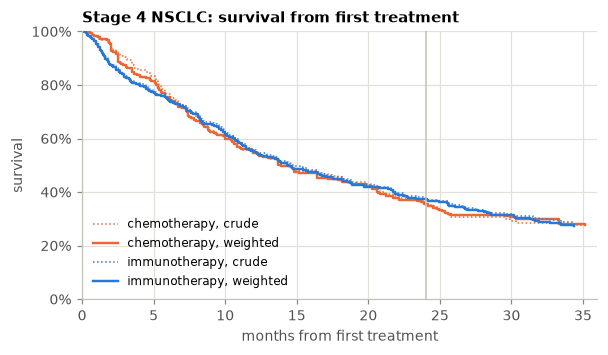

In [15]:
cur = pd.read_csv(RES / "causal" / "weighted_km_curves.csv")
fig, ax = plt.subplots(figsize=(5.6, 3.3))
for (arm, wt), g in cur.groupby(["arm", "weights"]):
    col = SLOT[0] if arm == "immunotherapy" else SLOT[1]
    ax.step(np.r_[0, g.month], np.r_[1, g.S], where="post", color=col, lw=1.6 if wt == "weighted" else 1,
            ls="-" if wt == "weighted" else ":", label=f"{arm}, {wt}")
ax.axvline(24, color=AXIS, lw=1)
ax.set_xlim(0, 36); ax.set_ylim(0, 1); ax.set_xlabel("months from first treatment"); ax.set_ylabel("survival")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.legend(fontsize=8)
ax.set_title("Stage 4 NSCLC: survival from first treatment")
fig.tight_layout(); fig.savefig(FIG / "causal_km.pdf"); fig.savefig(FIG / "causal_km.png", dpi=200); plt.show()